# UpSet examples

In [1]:
%matplotlib inline
import random
import itemiset
from itemiset import load_example
pbody, decay = load_example("pbody")["sets"], load_example("decay")["sets"]

## P-body proximity labelling (3 sets)

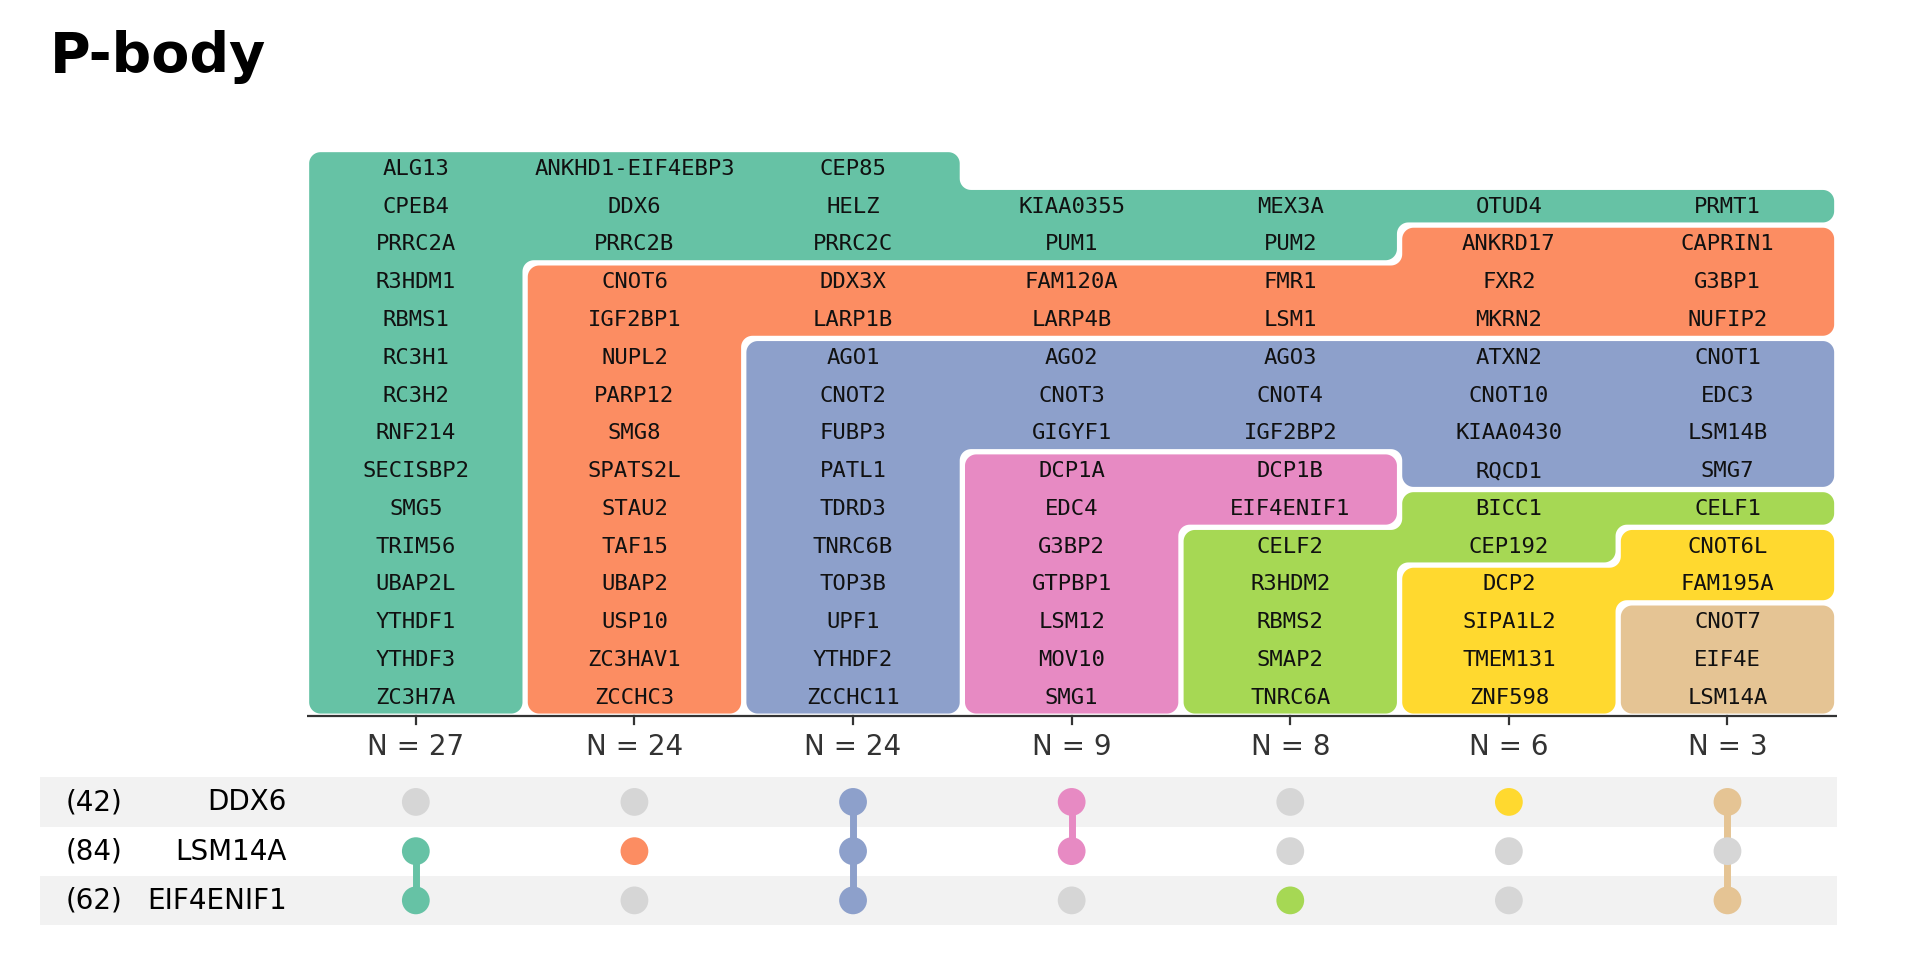

In [2]:
itemiset.upset(pbody, color_list="Set2", title="P-body")

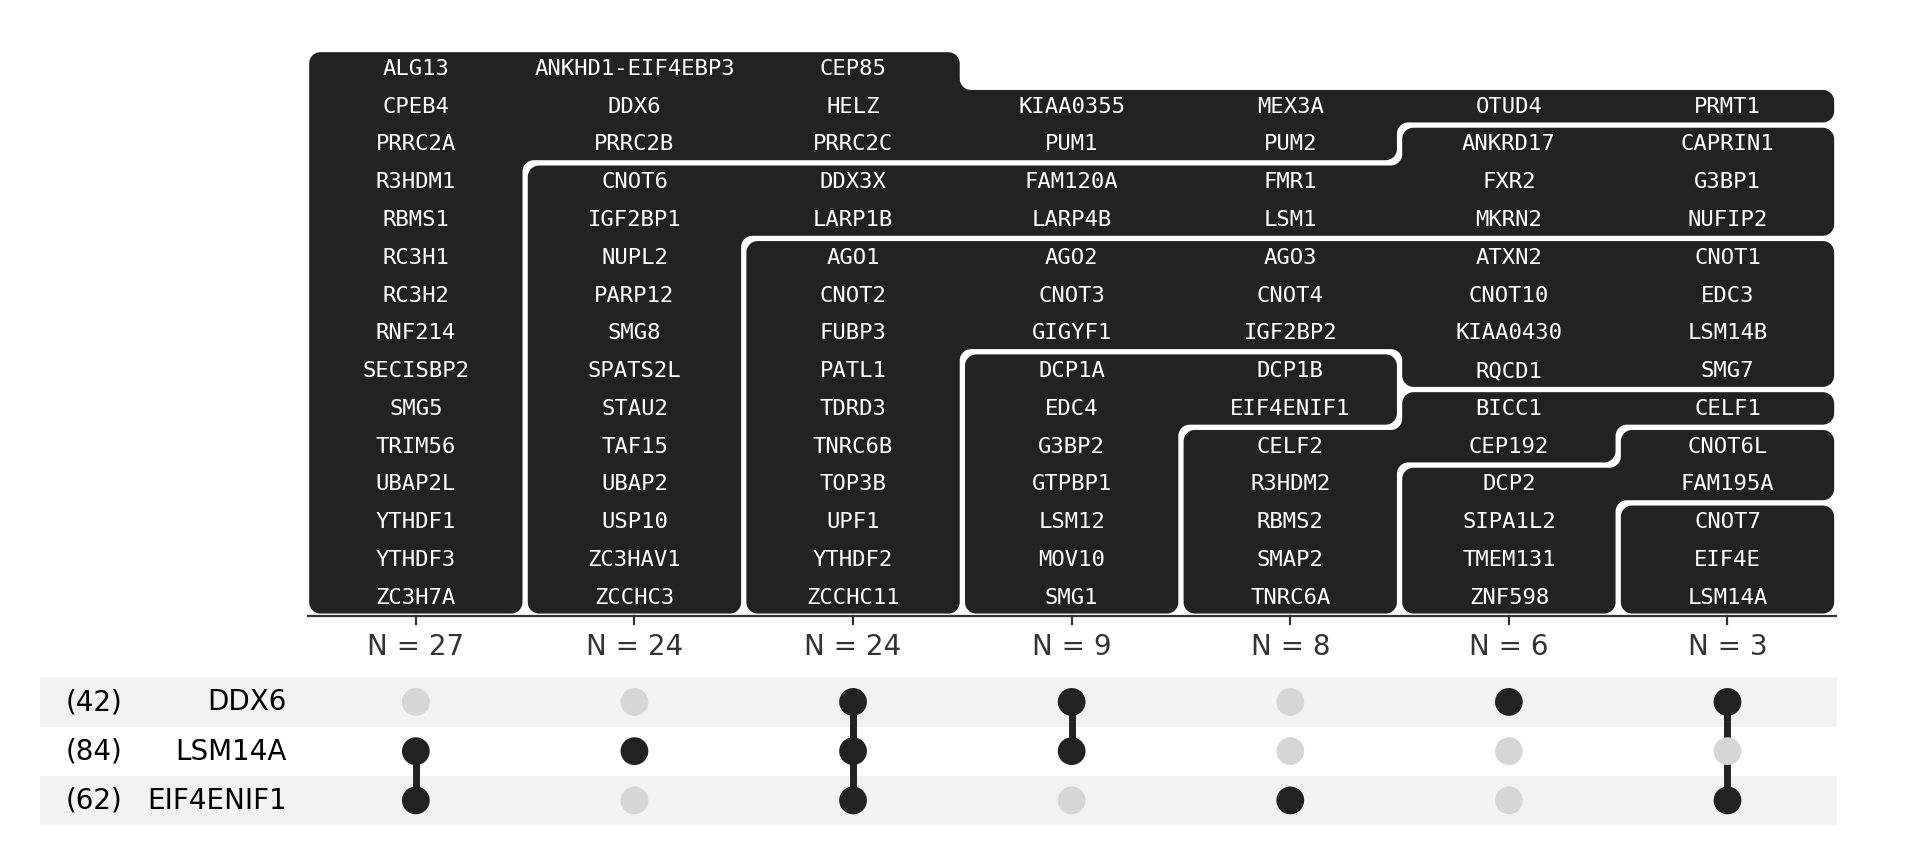

In [3]:
itemiset.upset(pbody)

## mRNA decay (3 sets)

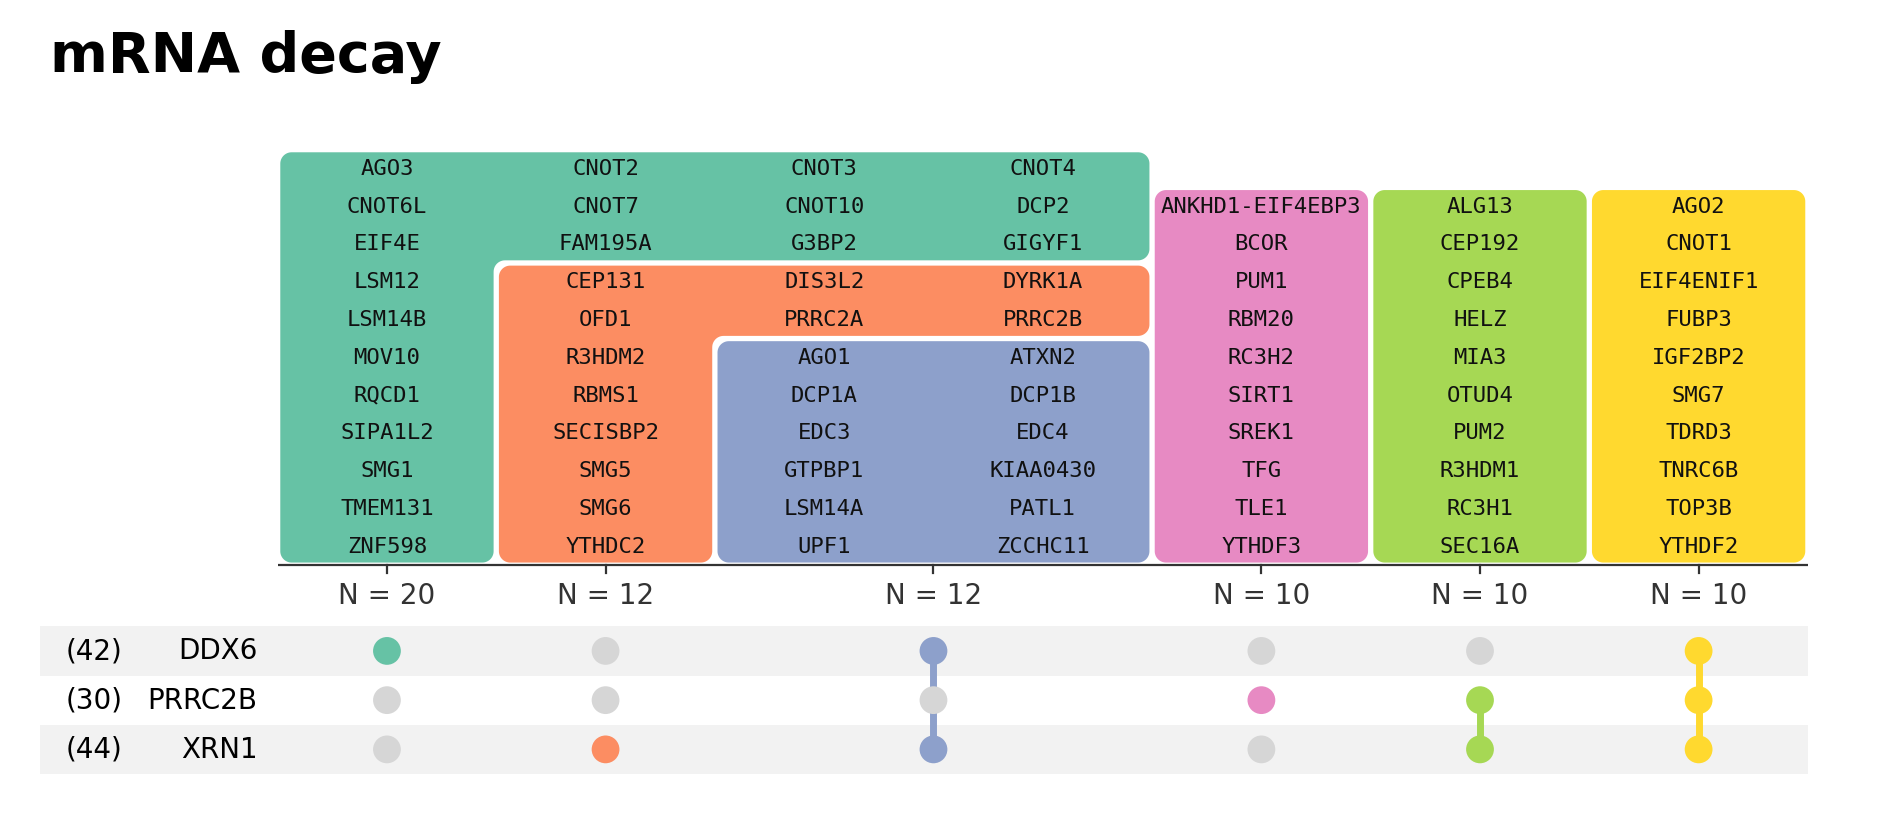

In [4]:
itemiset.upset(decay, color_list="Set2", title="mRNA decay")

## Five sets

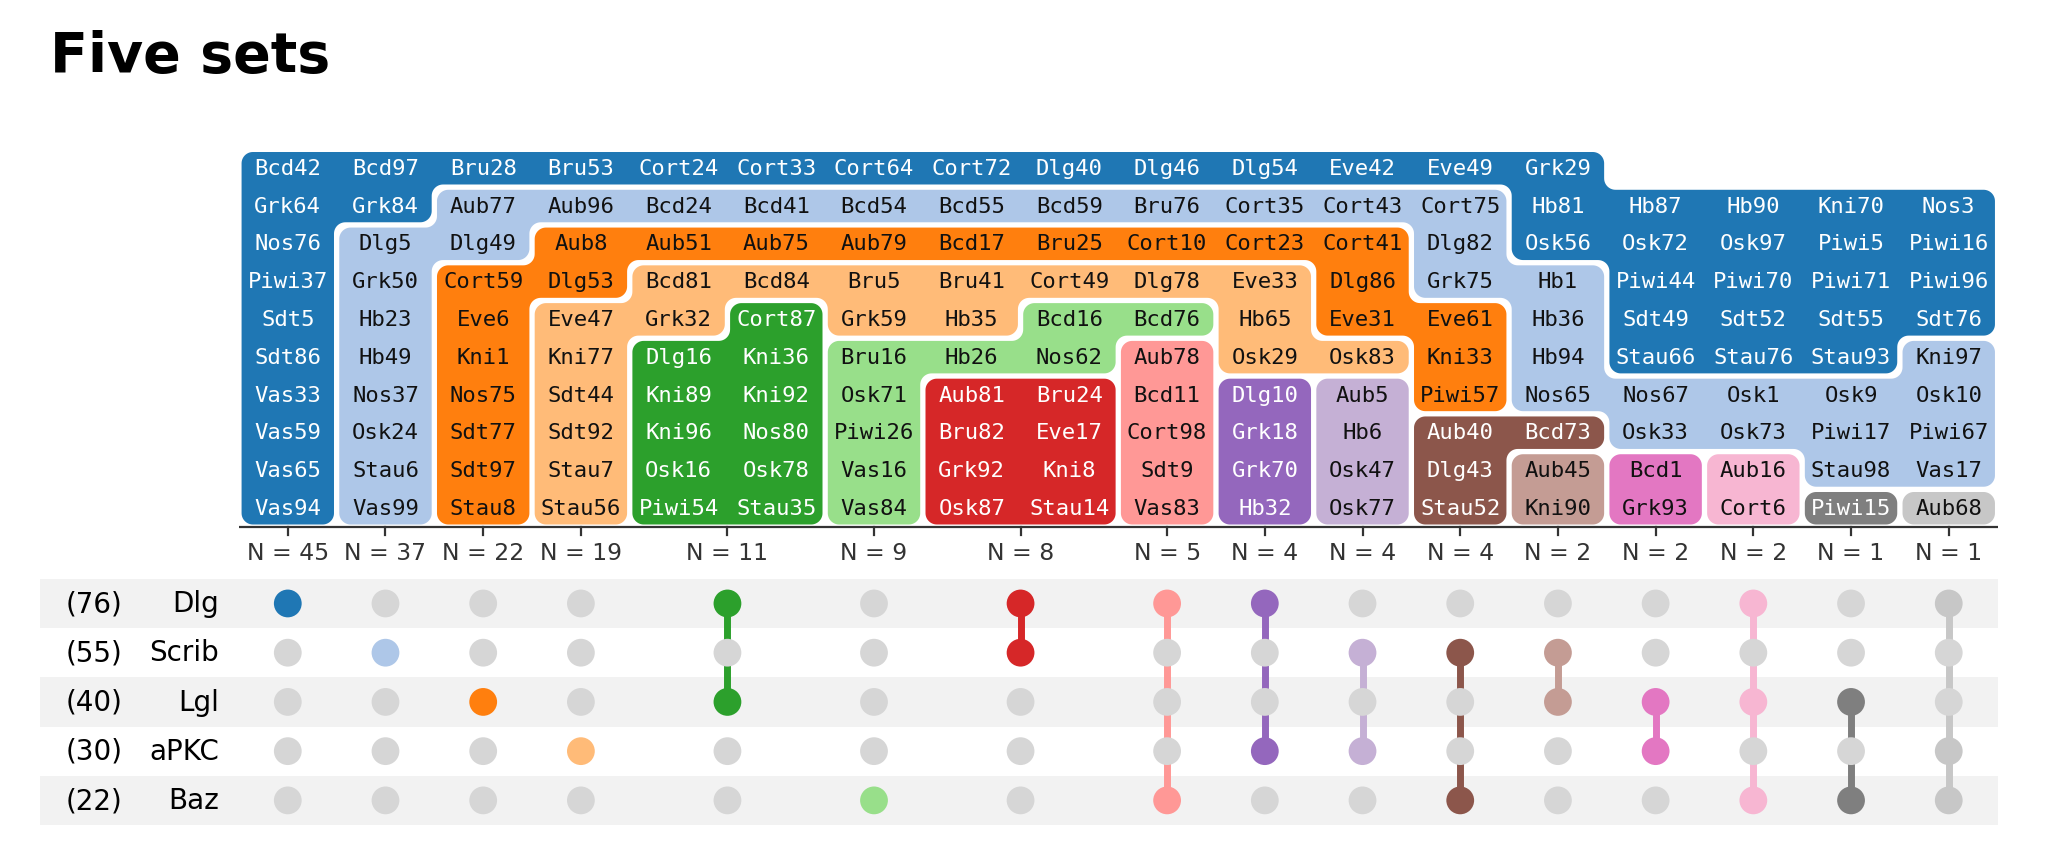

In [5]:
rng = random.Random(3)
roots = ["dlg", "sdt", "cort", "bru", "nos", "osk", "vas", "aub", "piwi", "stau", "grk", "bcd", "hb", "kni", "eve"]
pool = sorted({rng.choice(roots).capitalize() + str(rng.randint(1, 99)) for _ in range(400)})
five = {"Dlg": rng.sample(pool, 76), "Scrib": rng.sample(pool, 55), "Lgl": rng.sample(pool, 40),
        "aPKC": rng.sample(pool, 30), "Baz": rng.sample(pool, 22)}
itemiset.upset(five, color_list="tab20", title="Five sets")

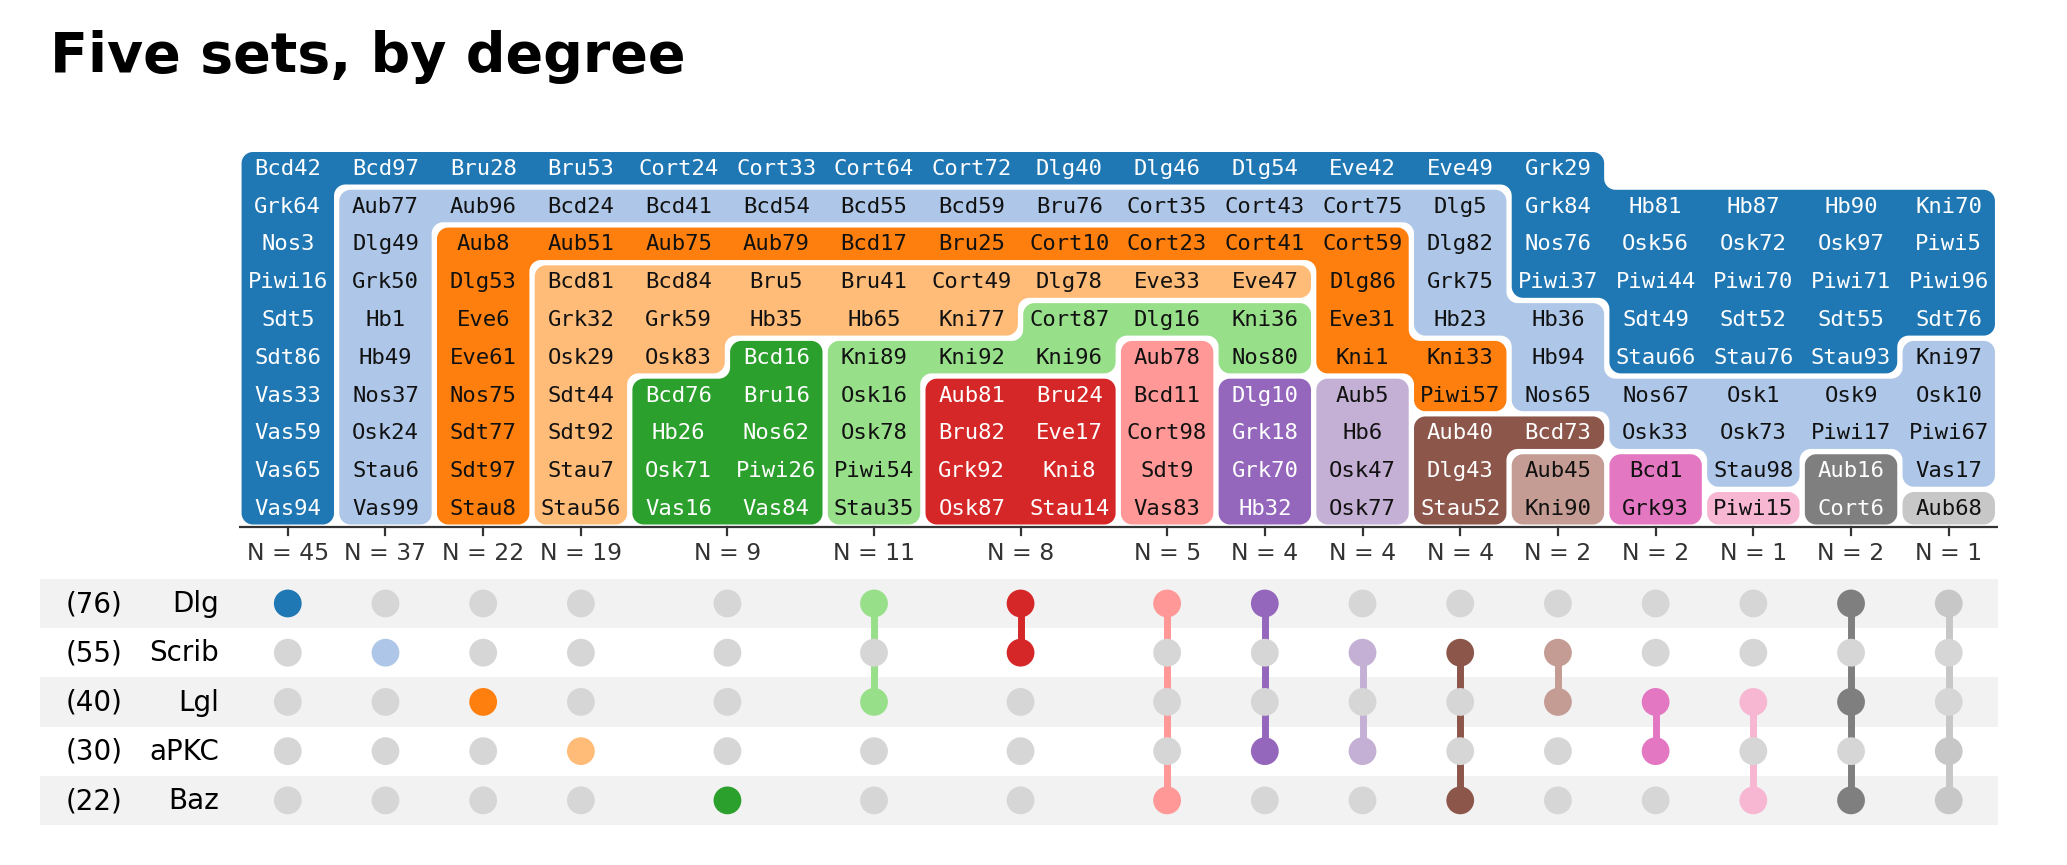

In [6]:
itemiset.upset(five, color_list="tab20", sort_by="degree", title="Five sets, by degree")

## Shape

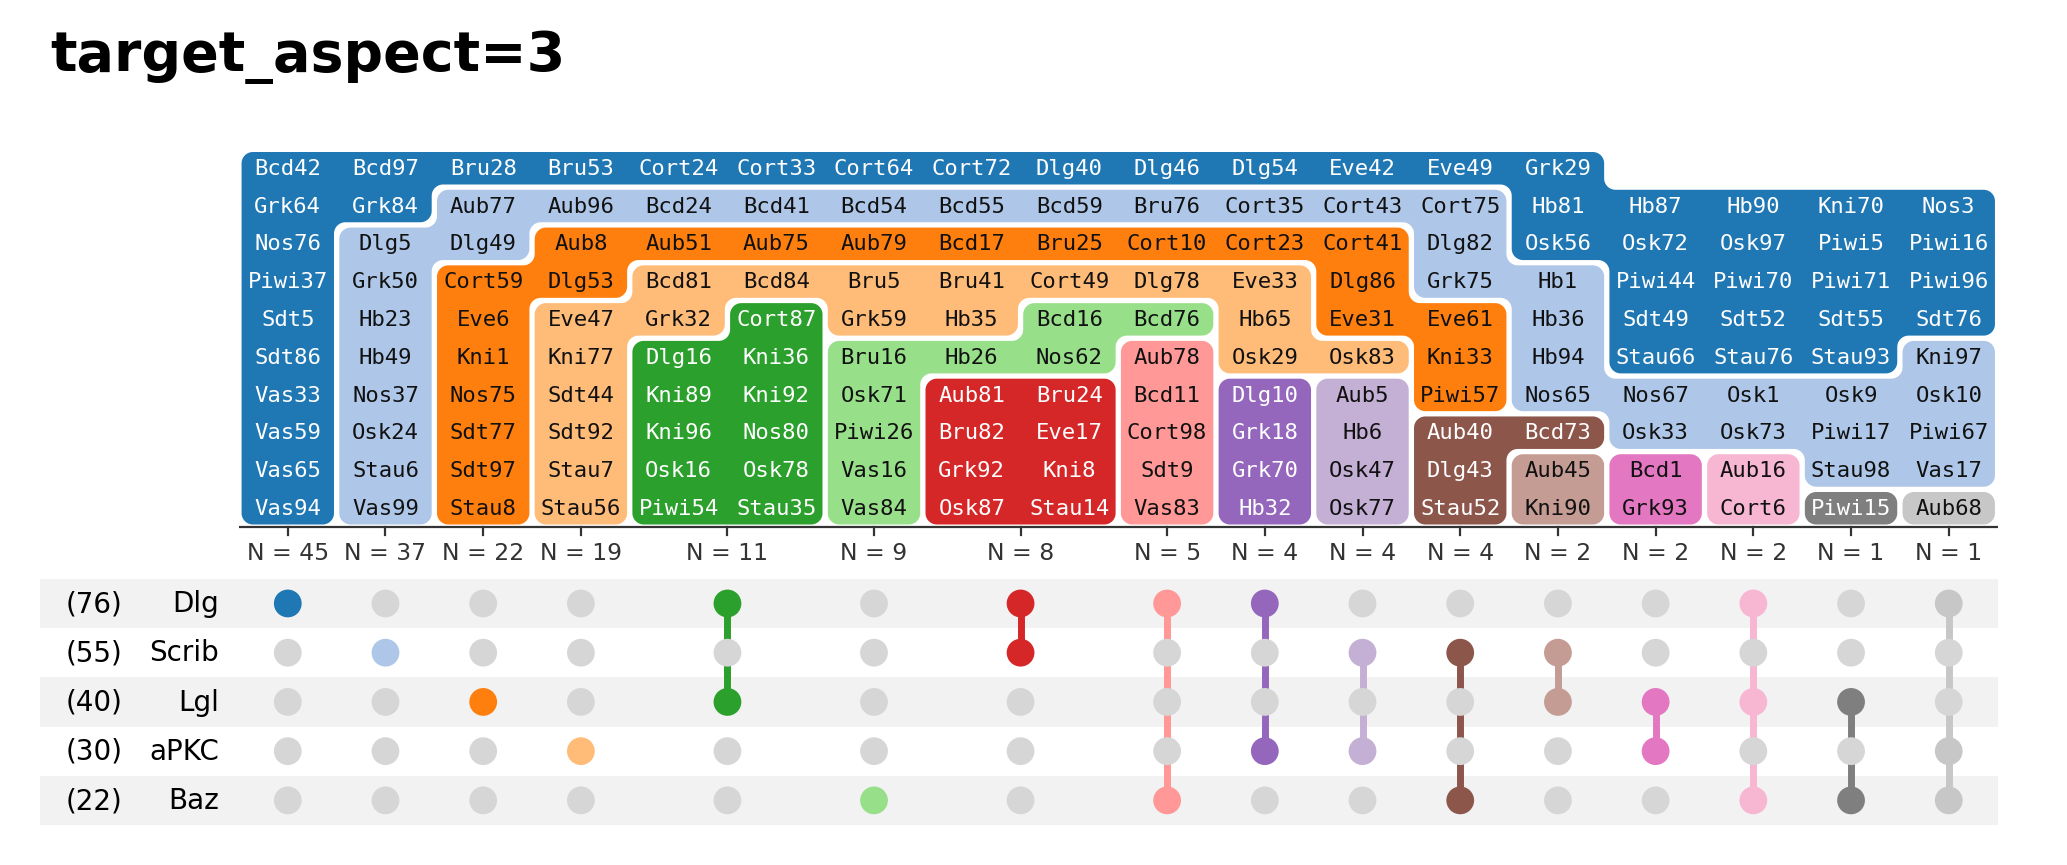

In [7]:
itemiset.upset(five, color_list="tab20", target_aspect=3, title="target_aspect=3")

## Prime numbers

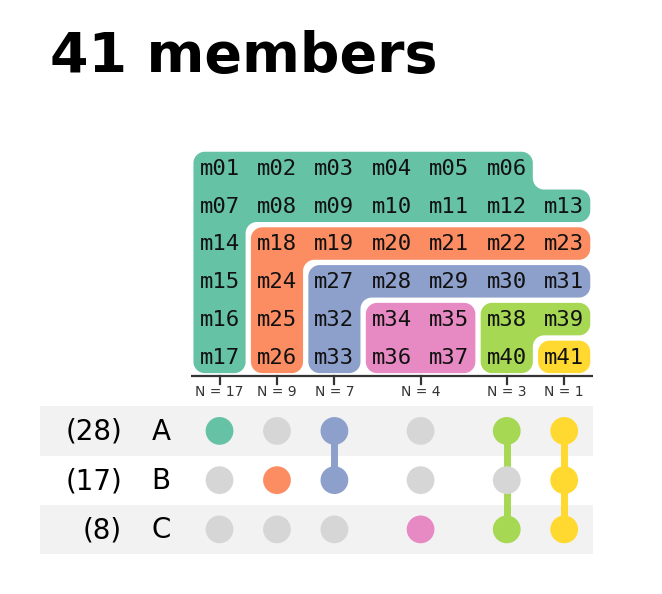

In [8]:
sizes = {("A",): 17, ("B",): 9, ("A", "B"): 7, ("C",): 4, ("A", "C"): 3, ("A", "B", "C"): 1}
prime, n = {"A": [], "B": [], "C": []}, 0
for zone, size in sizes.items():
    for _ in range(size):
        n += 1
        for s in zone:
            prime[s].append(f"m{n:02d}")
itemiset.upset(prime, color_list="Set2", title="41 members")

## Packing styles

Two other ways to spill the bars, each drawn with three seeds. They are a demo only: each one stands in for `plan_grid`, which returns the foot widths, rows and cells of every bar.

**Seeds:** the default packing has no randomness, so the same sets always give the same picture. Only random styles like the two below depend on a seed. (The five sets themselves are made up with `random.Random(3)`.)

In [9]:
from unittest.mock import patch
from itemiset.upset_plot import plan_grid, _connected, _outline

def show(style, title):
    "Draw the five sets with `style` in place of `plan_grid`."
    with patch("itemiset.upset_plot.plan_grid", style):
        return itemiset.upset(five, color_list="tab20", title=title)

def result(cells):
    "Foot widths, rows and cells, as `plan_grid` returns them."
    return [sum(r == 0 for _, r in cs) for cs in cells], 1 + max(r for cs in cells for _, r in cs), cells

def nbrs(c, r):
    return ((c + 1, r), (c - 1, r), (c, r + 1), (c, r - 1))

**Random pour:** pouring again, but each bar's foot width and side are picked at random, trying again until everything fits. Three seeds.

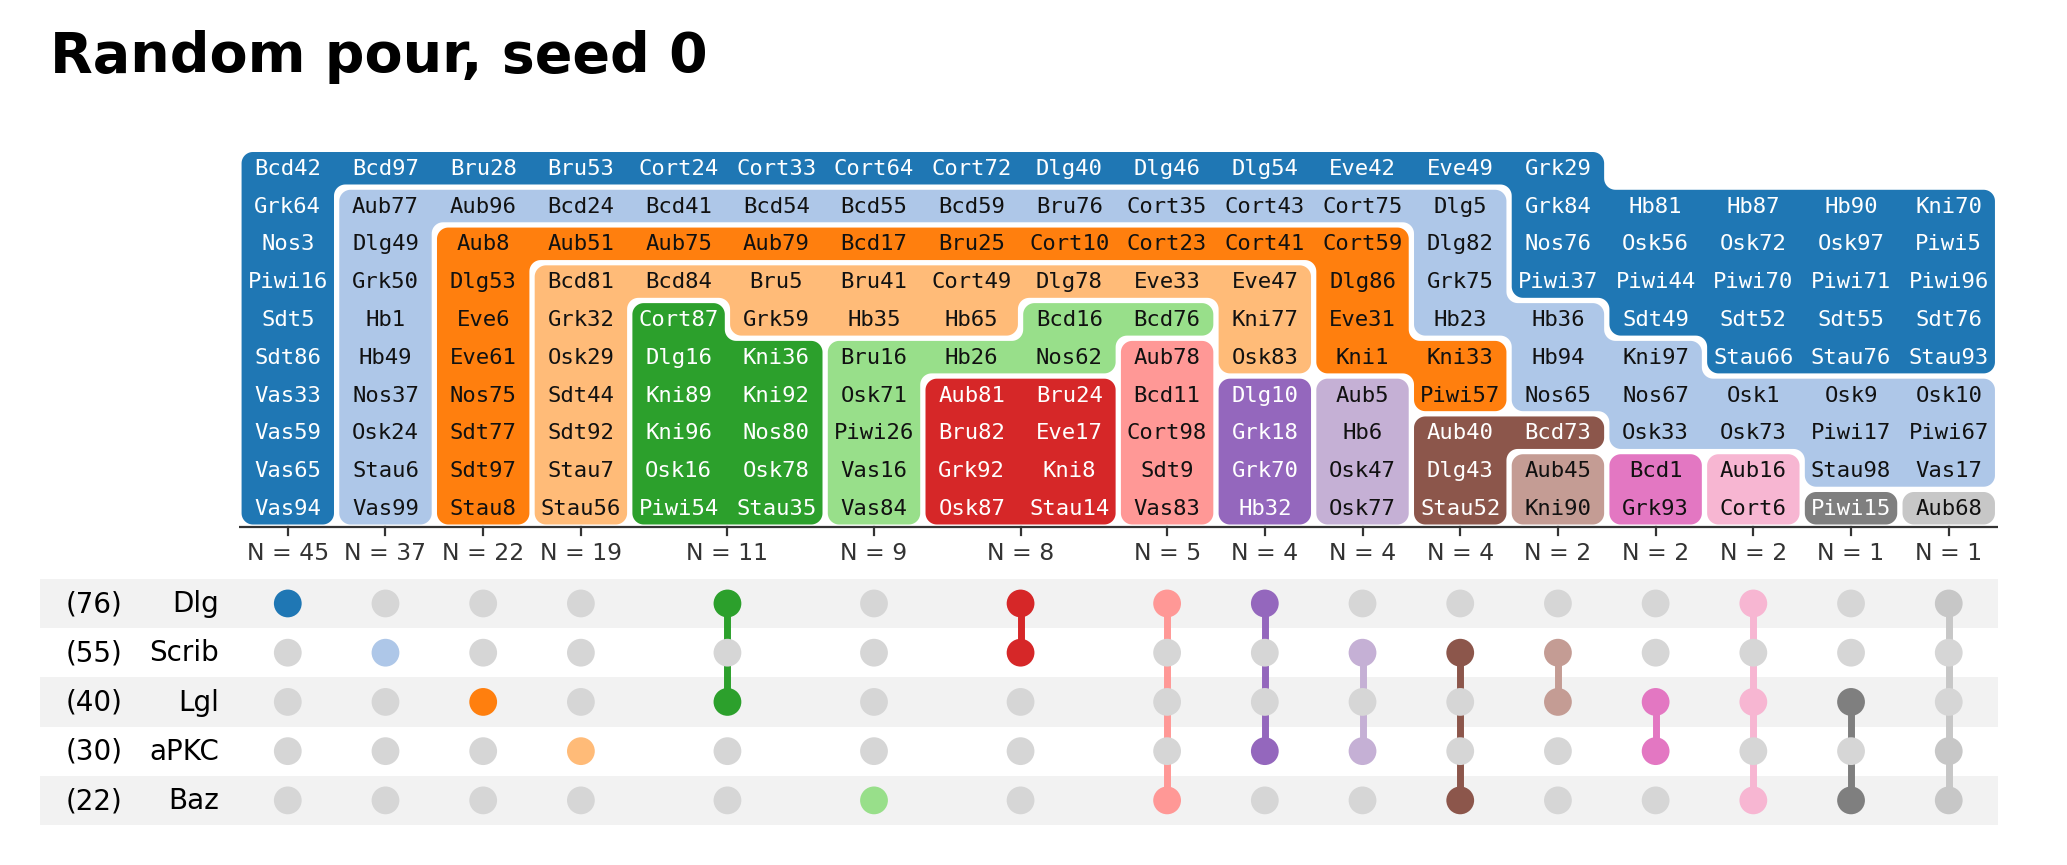

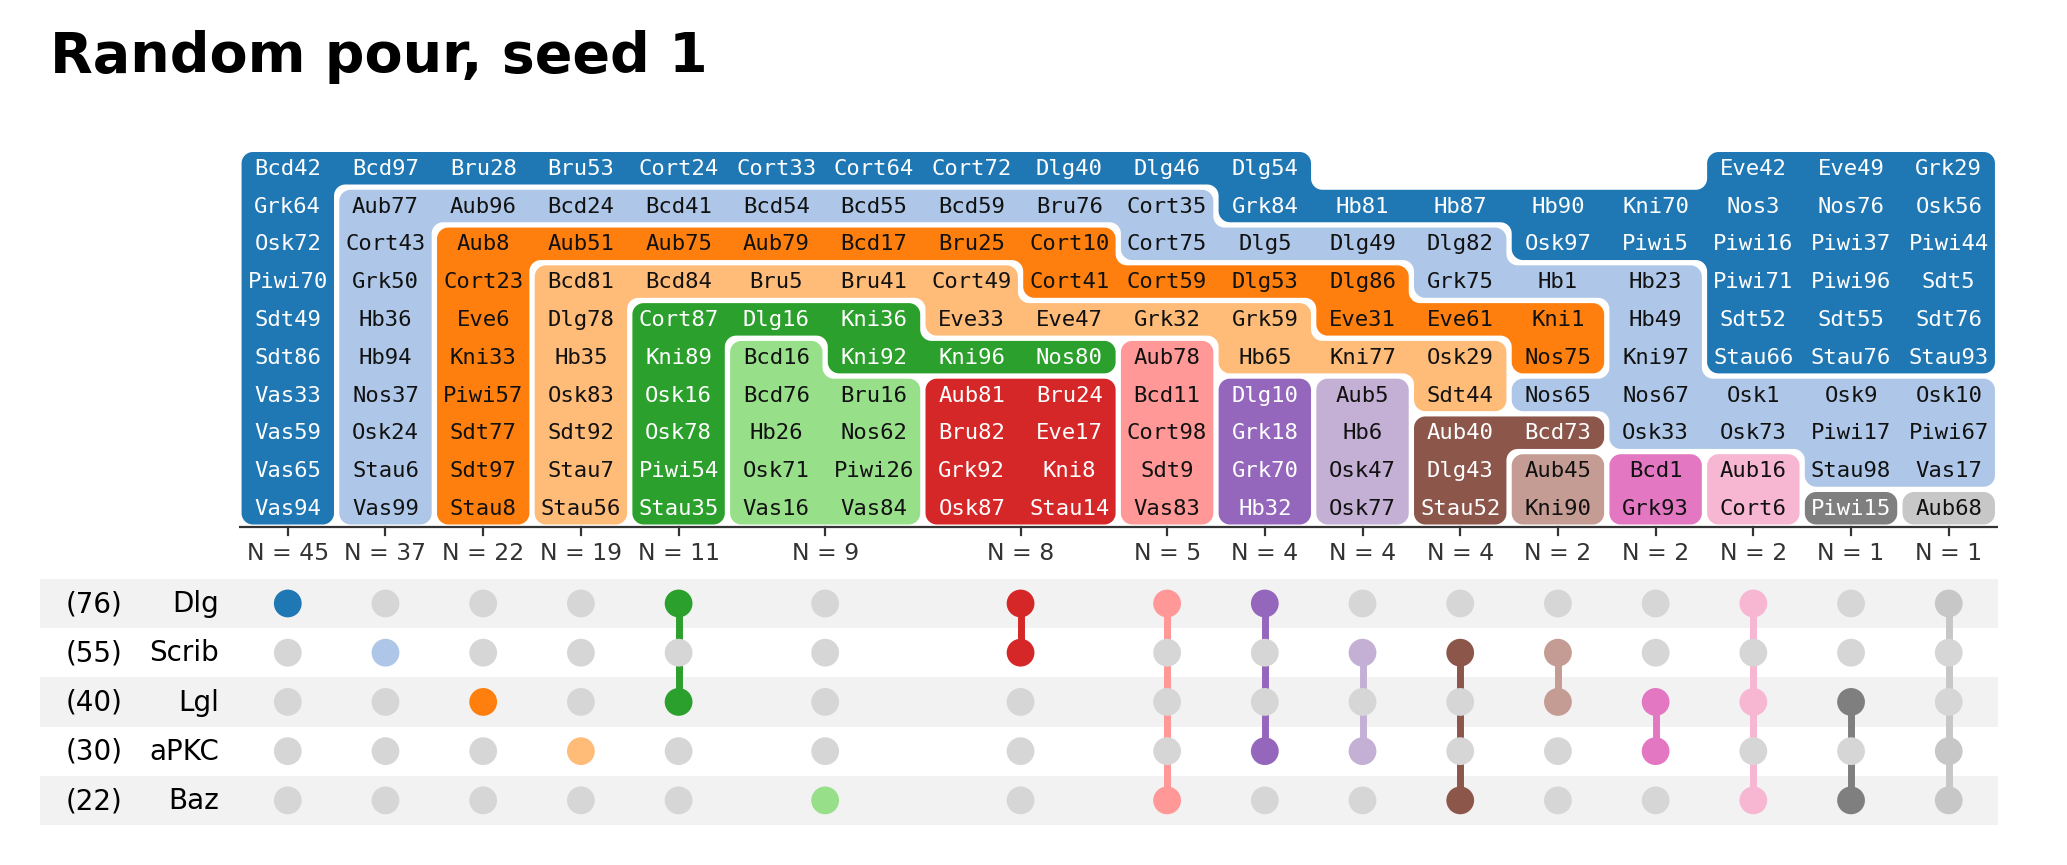

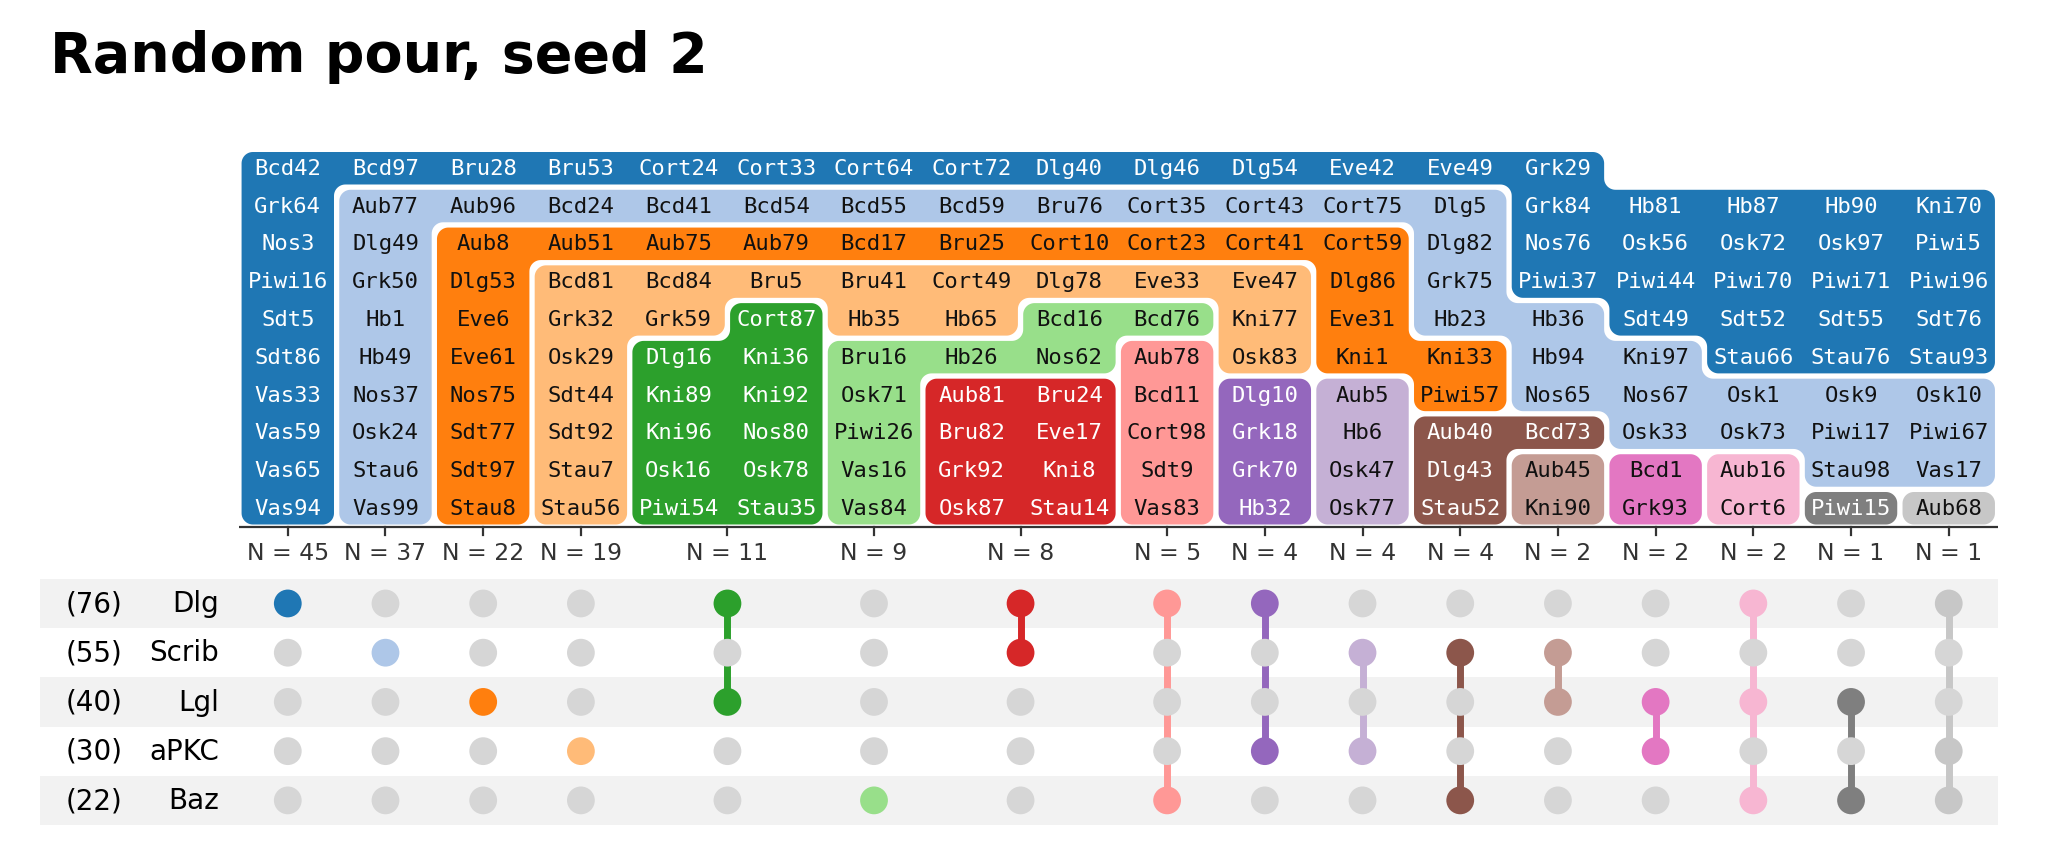

In [10]:
from itemiset.upset_plot import _pour, _reachable

def random_pour(seed):
    def style(counts, aspect, target):
        widths, R, _ = plan_grid(counts, aspect, target)
        C, k, rng = sum(widths), len(counts), random.Random(seed)
        while True:
            w = [1] * k                                   # random foot widths, bigger bars likelier to widen
            while sum(w) < C:
                w[rng.choices(range(k), [n * (w[i] < n) for i, n in enumerate(counts)])[0]] += 1
            taken, cells, L = frozenset(), [], C
            for i in reversed(range(k)):                  # smallest bar first, as in `pack_bars`
                cs = _pour(counts[i], L - w[i], w[i], R, C, taken, rng.choice((1, -1)))
                if cs is None or (i and not _reachable(L - w[i], R, C, taken | set(cs))):
                    break
                taken, cells, L = taken | set(cs), [cs] + cells, L - w[i]
            else:
                return result(cells)
    return style

for s in (0, 1, 2):
    display(show(random_pour(s), f"Random pour, seed {s}"))

**Tidy:** start from the default and keep swapping cells between touching bars when it shortens their outlines (a cheap stand-in for an exact solver). Random too, so it depends on the seed.

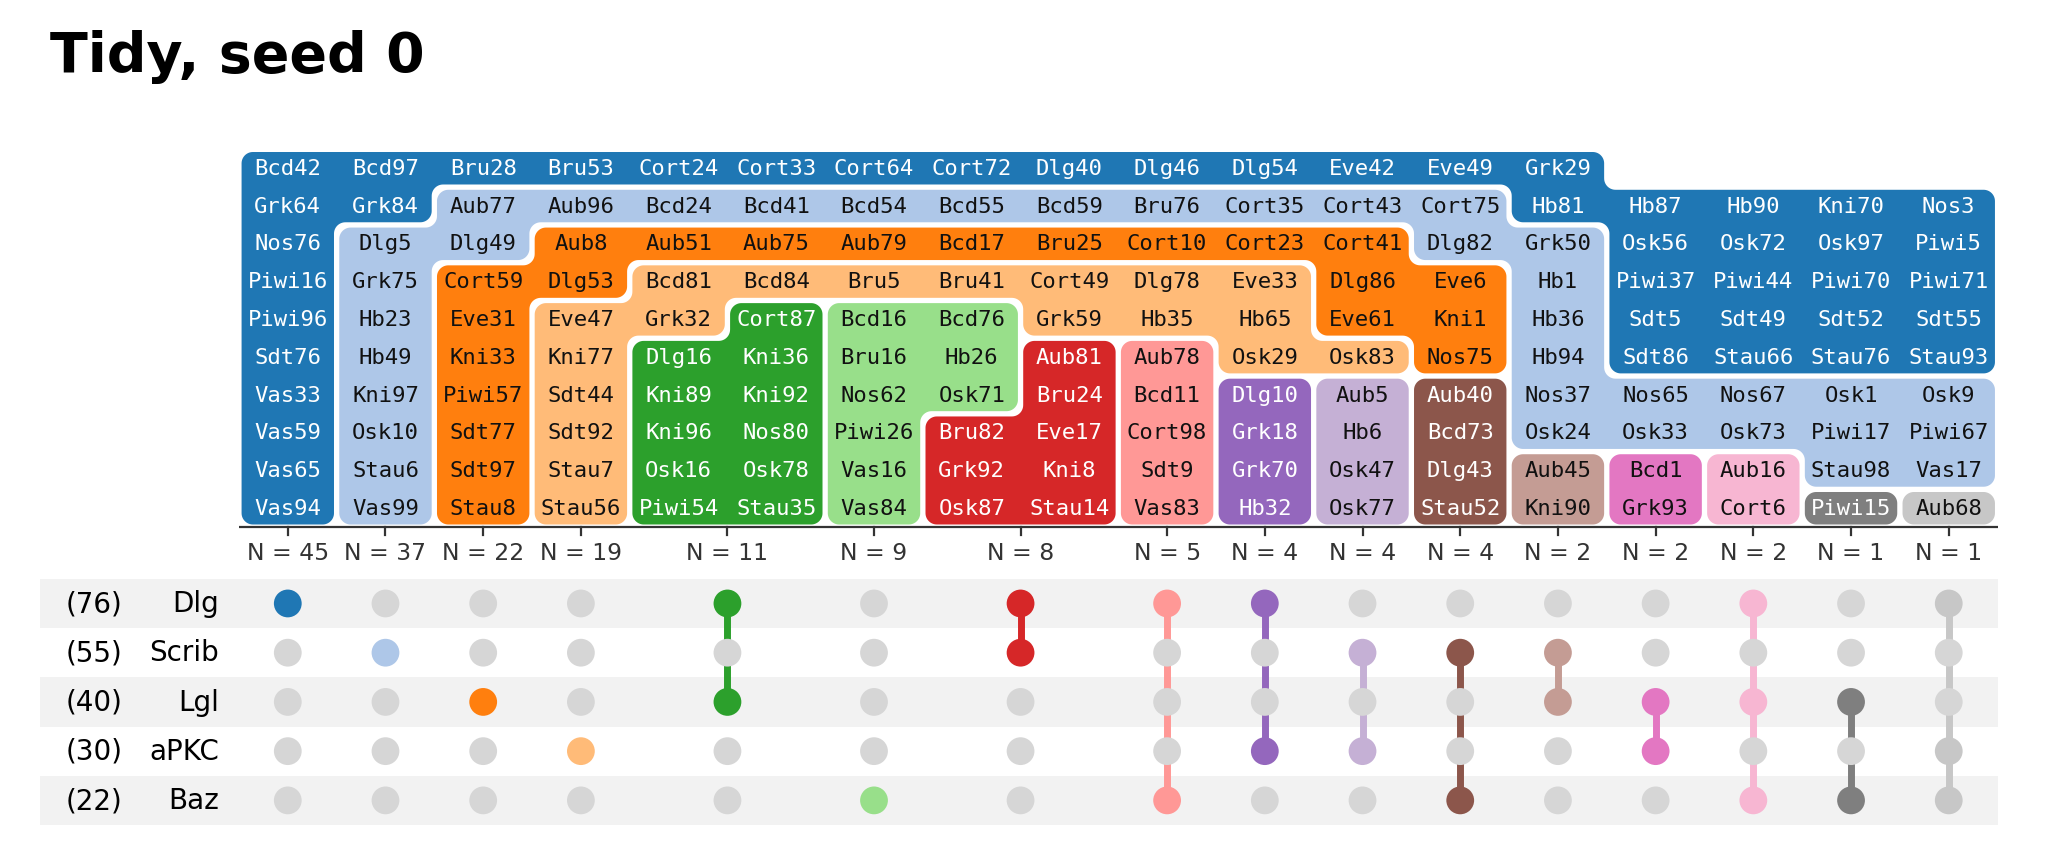

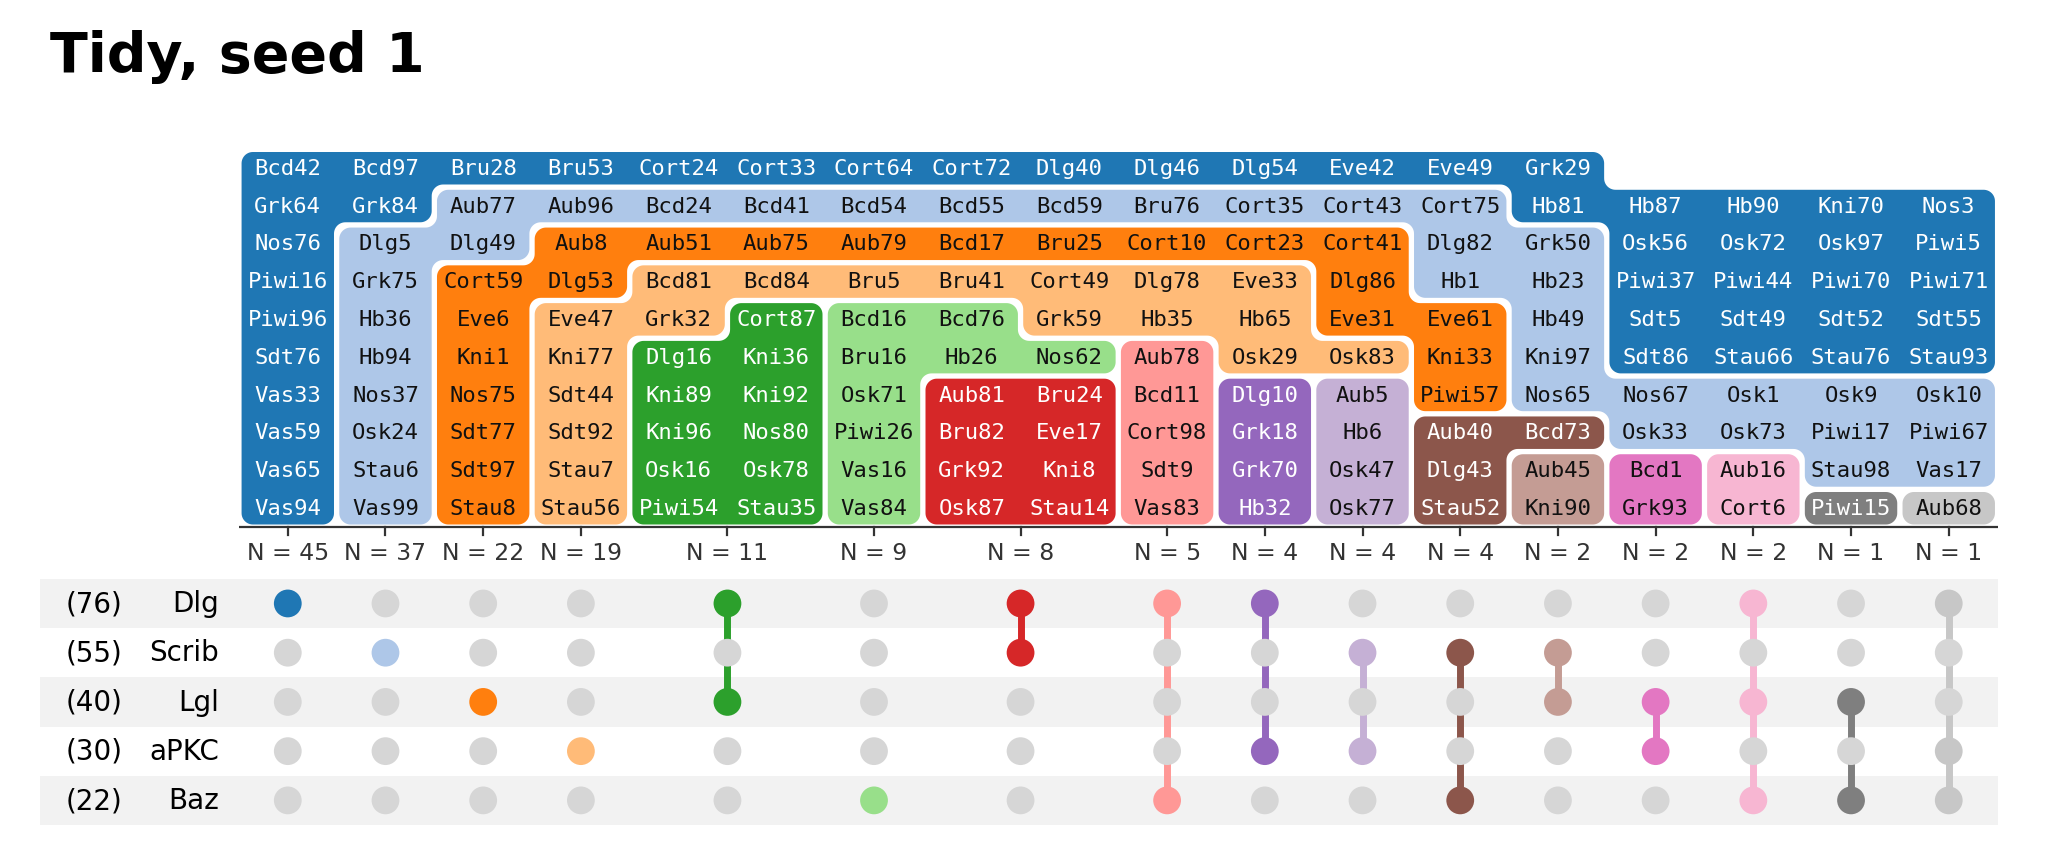

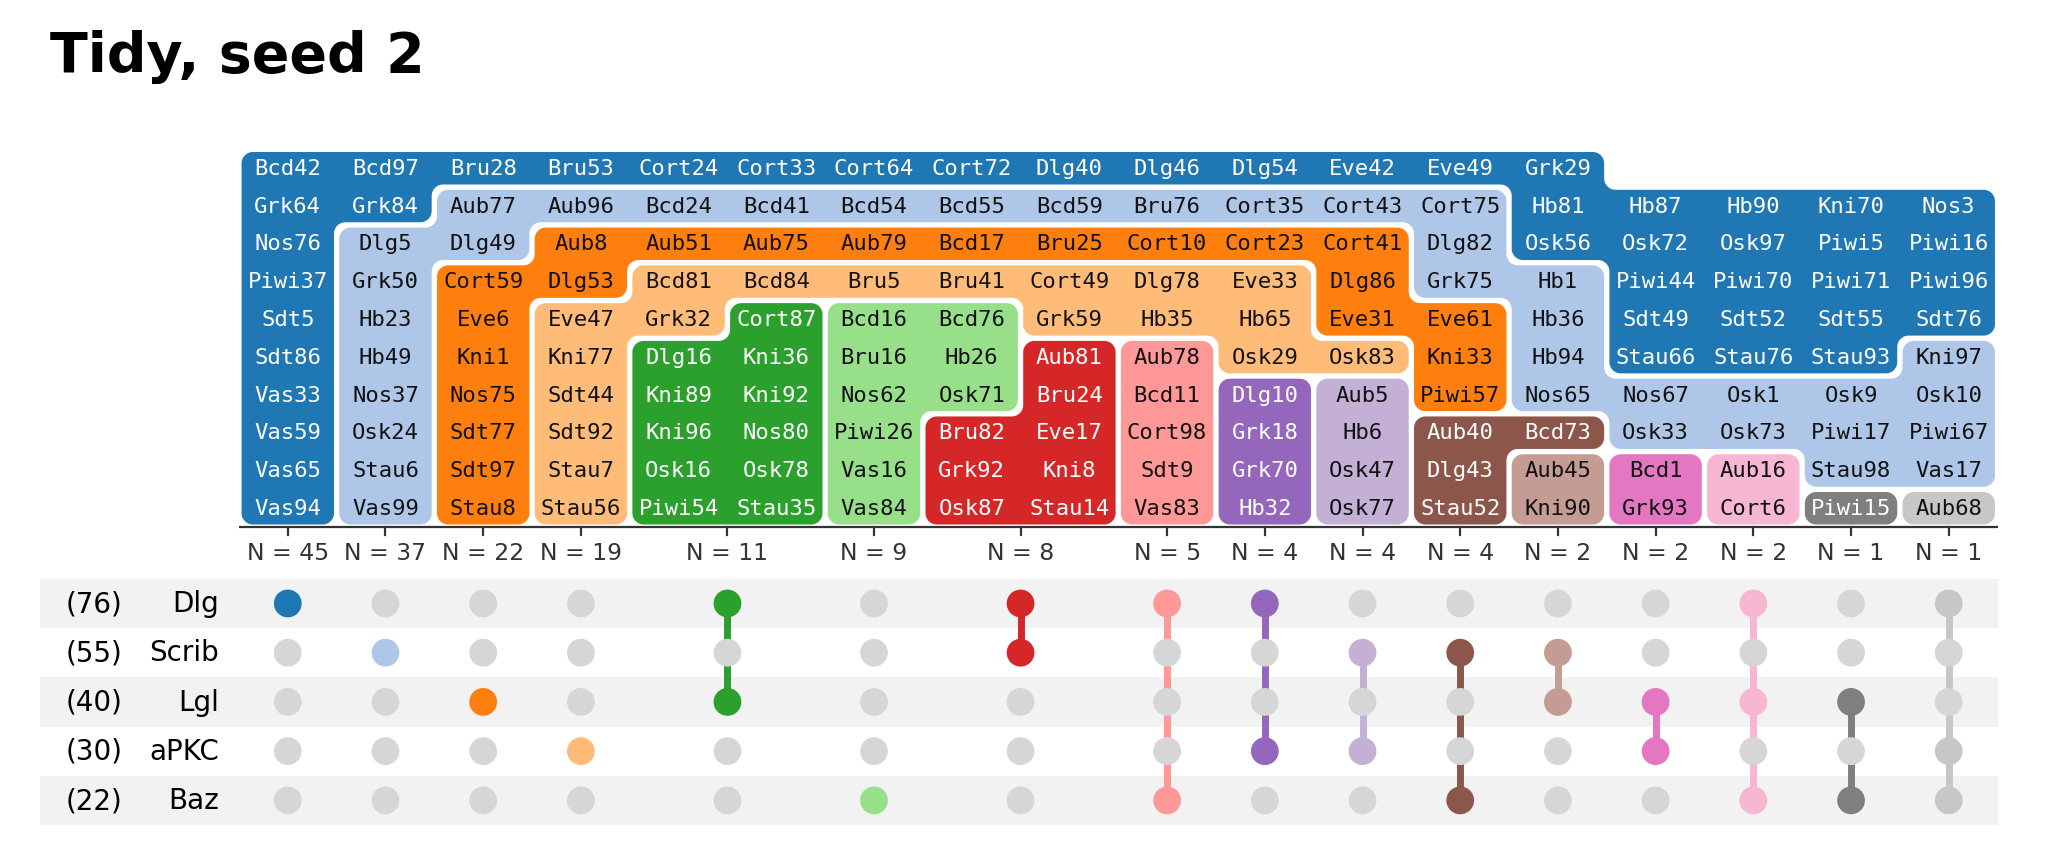

In [11]:
def tidy(seed, steps=6000):
    def style(counts, aspect, target):
        _, _, cells = plan_grid(counts, aspect, target)
        bars, rng = [set(cs) for cs in cells], random.Random(seed)
        own = {p: i for i, b in enumerate(bars) for p in b}
        for _ in range(steps):
            p = rng.choice(list(own))
            j = own.get(rng.choice(nbrs(*p)))
            i = own[p]
            if p[1] == 0 or j is None or j == i:
                continue
            edge = [x for x in bars[j] if x[1] > 0 and any(own.get(y) == i for y in nbrs(*x))]
            if not edge:
                continue
            q = rng.choice(edge)
            before = _outline(bars[i]) + _outline(bars[j])
            bars[i] ^= {p, q}; bars[j] ^= {p, q}
            if _connected(list(bars[i])) and _connected(list(bars[j])) and _outline(bars[i]) + _outline(bars[j]) <= before:
                own[p], own[q] = j, i
            else:
                bars[i] ^= {p, q}; bars[j] ^= {p, q}
        return result([sorted(b) for b in bars])
    return style

for s in (0, 1, 2):
    display(show(tidy(s), f"Tidy, seed {s}"))